# CITS5508 - Assignment 1 2026

## Part 1: Softmax Regression

**1. Load the MNIST dataset from OpenML using scikit-learn**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False)
y = y.astype(int)

**2. Display some examples from the dataset. Describe what features and labels represent.**

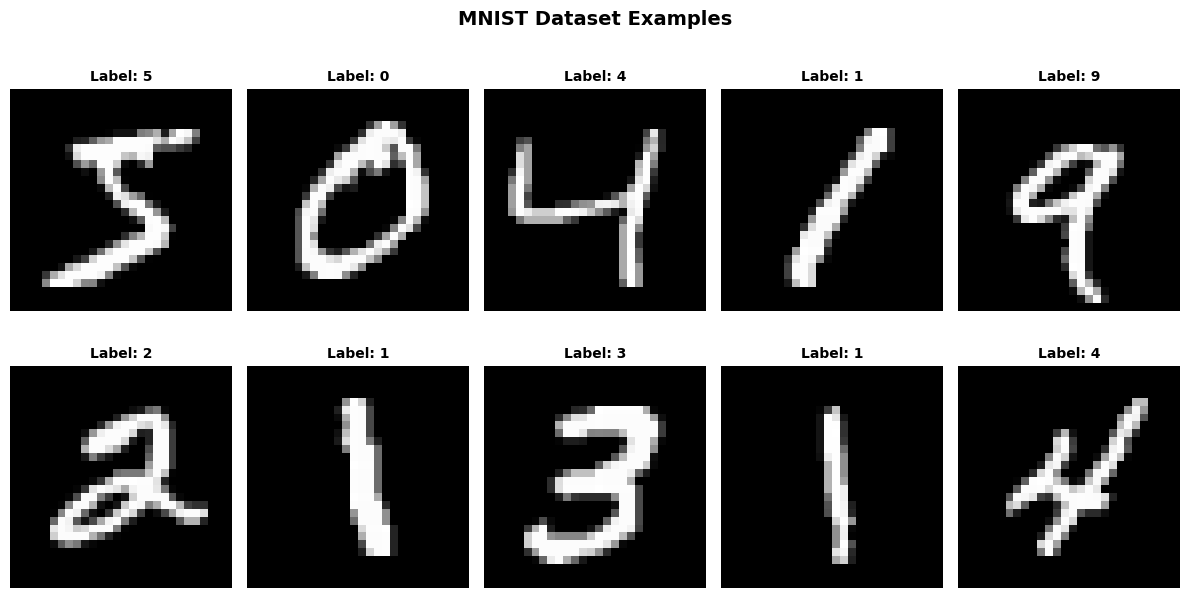

In [2]:
# display some examples from the dataset
plt.figure(figsize=(12, 6.5))
plt.suptitle("MNIST Dataset Examples", fontsize=14, fontweight="bold")
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X[i].reshape(28, 28), cmap="gray")
    plt.title(f"Label: {int(y[i])}", fontsize=10, fontweight="bold")
    plt.axis("off")

plt.tight_layout()
plt.show()

The MNIST dataset consists of 70,000 grayscale images where each each represents a single handwritten digit. The images have a fixed resolution of 28x28 pixels and each image contains 784 numerical features. Thus, the features are the pixel intensity values (out of 784) and the labels are which number from 0 to 9 each image corresponds to.

**3. Split the dataset into a training, validation, and test set. You should use 70% of the data for training, 15% for validation, and 15% for testing.**

In [3]:
from sklearn.model_selection import train_test_split

# split the data into training and temp sets
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# split temp into validation and testing sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# normalize the data
X_train = X_train / 255.0
X_val = X_val / 255.0
X_test = X_test / 255.0

print("Train shape:", X_train.shape, y_train.shape)
print("Validation shape:", X_val.shape, y_val.shape)
print("Test shape:", X_test.shape, y_test.shape)

Train shape: (49000, 784) (49000,)
Validation shape: (10500, 784) (10500,)
Test shape: (10500, 784) (10500,)


**(a) Display the class distribution in the training, validation, and test sets**

In [4]:
import numpy as np
import pandas as pd

def show_class_distribution(labels, name):
    classes, counts = np.unique(labels, return_counts=True)
    proportions = counts / counts.sum()

    df = pd.DataFrame({
        "Class": classes,
        "Count": counts,
        "Proportion": proportions
    })

    print(f"\n{name} class distribution:")
    display(df)

show_class_distribution(y_train, "Training")
show_class_distribution(y_val, "Validation")
show_class_distribution(y_test, "Test")


Training class distribution:


,Class,Count,Proportion
0,0,4832,0.098612
1,1,5514,0.112531
2,2,4893,0.099857
3,3,4999,0.102020
4,4,4777,0.097490
5,5,4419,0.090184
6,6,4813,0.098224
7,7,5105,0.104184
8,8,4777,0.097490
9,9,4871,0.099408



Validation class distribution:


,Class,Count,Proportion
0,0,1036,0.098667
1,1,1182,0.112571
2,2,1048,0.099810
3,3,1071,0.102000
4,4,1023,0.097429
5,5,947,0.090190
6,6,1031,0.098190
7,7,1094,0.104190
8,8,1024,0.097524
9,9,1044,0.099429



Test class distribution:


,Class,Count,Proportion
0,0,1035,0.098571
1,1,1181,0.112476
2,2,1049,0.099905
3,3,1071,0.102000
4,4,1024,0.097524
5,5,947,0.090190
6,6,1032,0.098286
7,7,1094,0.104190
8,8,1024,0.097524
9,9,1043,0.099333


**(b) Do you need to stratify your split? Why or why not?**

Stratification is not necessary for this dataset, but it is a good practice to uphold for multiclass classification problems. Stratified sampling is when the population is divided into groups, and then samples are randomly seelcted from the group in proportion to their representation in the entire population. This is particularly important when a dataset is imbalanced, because a completely random split might mean that the training set is not actually representative of the data. Since the MNIST dataset is balanced, with each digit having nearly the same number of samples, a random split without stratification would be fine too.

**4. Implement softmax regression with gradient descent using vectorised NumPy code. Implement early stopping based on the validation set. Do not use scikit-learn for this task – only NumPy and basic Python.**


In [5]:
import numpy as np

# making sure the labels are ints before one-hot encoding
y_train = y_train.astype(int)
y_val = y_val.astype(int)

# adding a bias column so the model can learn an intercept as well
X_train_bias = np.c_[np.ones((X_train.shape[0], 1)), X_train]
X_val_bias = np.c_[np.ones((X_val.shape[0], 1)), X_val]

# one-hot encoding the labels for softmax regression
num_classes = 10
y_train_one_hot = np.eye(num_classes)[y_train]
y_val_one_hot = np.eye(num_classes)[y_val]

# starting the weights off small and random
rng = np.random.default_rng(42)
weights = rng.normal(0, 0.01, size=(X_train_bias.shape[1], num_classes))

# helper function for softmax
def softmax(score_matrix):
    # subtracting the row max prevents exponentials blowup
    shifted_scores = score_matrix - np.max(score_matrix, axis=1, keepdims=True)
    exp_scores = np.exp(shifted_scores)
    return exp_scores / np.sum(exp_scores, axis=1, keepdims=True)

# helper function for cross-entropy loss
def cross_entropy_loss(y_true, y_pred):
    # clipping avoids log(0), which would ruin everything
    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
    return -np.mean(np.sum(y_true * np.log(y_pred), axis=1))

# training settings
learning_rate = 0.1
max_epochs = 500
patience = 10

# storing the loss values so we can plot them later
training_loss_history = []
validation_loss_history = []

# early stopping setup
best_weights = weights.copy()
best_val_loss = np.inf
epochs_without_improvement = 0

for epoch in range(max_epochs):
    # scores are just X dot W
    train_scores = X_train_bias @ weights
    val_scores = X_val_bias @ weights

    # convert scores into probabilities with softmax
    train_probs = softmax(train_scores)
    val_probs = softmax(val_scores)

    # calculate the cross-entropy loss for both sets
    train_loss = cross_entropy_loss(y_train_one_hot, train_probs)
    val_loss = cross_entropy_loss(y_val_one_hot, val_probs)

    training_loss_history.append(train_loss)
    validation_loss_history.append(val_loss)

    # checking whether validation loss improved
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = weights.copy()
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    # if validation loss stops improving, stop early
    if epochs_without_improvement >= patience:
        print(f"Early stopping triggered at epoch {epoch + 1}")
        break

    # vectorised gradient for softmax regression
    gradient = (X_train_bias.T @ (train_probs - y_train_one_hot)) / X_train_bias.shape[0]

    # gradient descent update
    weights = weights - learning_rate * gradient

    # just printing every 10 epochs so it is easier to see what is going on
    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1}: "
            f"training loss = {train_loss:.4f}, "
            f"validation loss = {val_loss:.4f}"
        )

# restoring the best weights seen during training
weights = best_weights

Epoch 10: training loss = 1.5916, validation loss = 1.5955
Epoch 20: training loss = 1.2059, validation loss = 1.2121
Epoch 30: training loss = 1.0028, validation loss = 1.0103
Epoch 40: training loss = 0.8801, validation loss = 0.8884
Epoch 50: training loss = 0.7980, validation loss = 0.8069
Epoch 60: training loss = 0.7389, validation loss = 0.7482
Epoch 70: training loss = 0.6941, validation loss = 0.7038
Epoch 80: training loss = 0.6589, validation loss = 0.6688
Epoch 90: training loss = 0.6303, validation loss = 0.6404
Epoch 100: training loss = 0.6065, validation loss = 0.6169
Epoch 110: training loss = 0.5864, validation loss = 0.5970
Epoch 120: training loss = 0.5692, validation loss = 0.5799
Epoch 130: training loss = 0.5542, validation loss = 0.5651
Epoch 140: training loss = 0.5409, validation loss = 0.5520
Epoch 150: training loss = 0.5292, validation loss = 0.5404
Epoch 160: training loss = 0.5187, validation loss = 0.5301
Epoch 170: training loss = 0.5092, validation los

**(a) Display a plot showing how the training and validation loss changes over time for your model.**

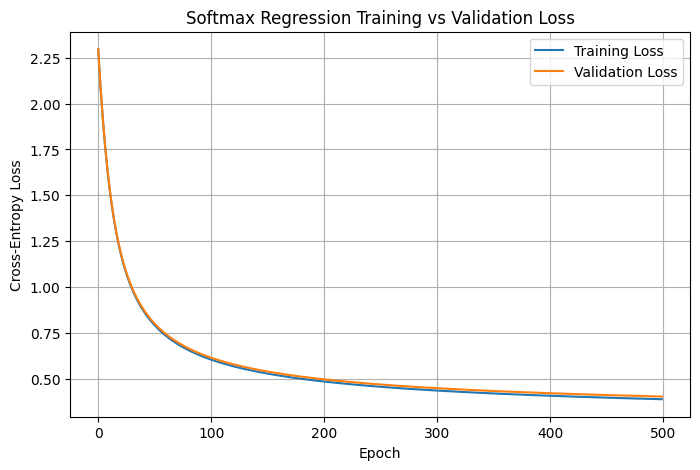

In [6]:
plt.figure(figsize=(8, 5))
plt.plot(training_loss_history, label="Training Loss")
plt.plot(validation_loss_history, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Softmax Regression Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

**(b) What do you observe? Is this what you expected?**

blah blah

**5. Fit a sklearn.linear model.LogisticRegression model to the data. Do not apply regularisation. Compare the performance of your softmax regression model to the scikit-learn model**

In [11]:
from sklearn.linear_model import LogisticRegression
import numpy as np

sklearn_log_reg = LogisticRegression(
    C=1e12,
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

sklearn_log_reg.fit(X_train, y_train)

# sklearn model predictions
sklearn_test_predictions = sklearn_log_reg.predict(X_test)

# custom softmax model predictions
X_test_bias = np.c_[np.ones((X_test.shape[0], 1)), X_test]
softmax_test_scores = X_test_bias @ weights
softmax_test_predictions = np.argmax(softmax_test_scores, axis=1)

print("Both models have now been evaluated on the test set.")

Both models have now been evaluated on the test set.


**(a) Display a confusion matrix for each model.**

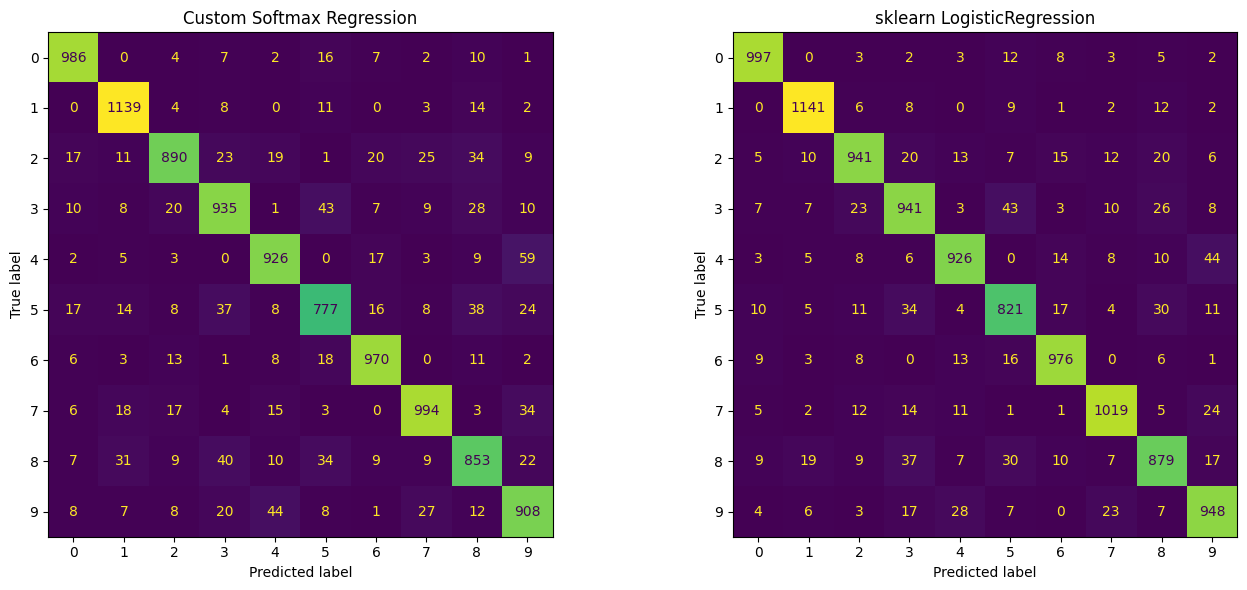

In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

softmax_conf_matrix = confusion_matrix(y_test, softmax_test_predictions)
sklearn_conf_matrix = confusion_matrix(y_test, sklearn_test_predictions)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ConfusionMatrixDisplay(softmax_conf_matrix).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Custom Softmax Regression")

ConfusionMatrixDisplay(sklearn_conf_matrix).plot(ax=axes[1], colorbar=False)
axes[1].set_title("sklearn LogisticRegression")

plt.tight_layout()
plt.show()

**(b) Show appropriate evaluation metrics for both models.**

In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report
import pandas as pd

def get_model_metrics(true_labels, predicted_labels, model_name):
    accuracy = accuracy_score(true_labels, predicted_labels)
    precision, recall, f1, _ = precision_recall_fscore_support(
        true_labels,
        predicted_labels,
        average="weighted",
        zero_division=0
    )
    
    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision (weighted)": precision,
        "Recall (weighted)": recall,
        "F1-score (weighted)": f1
    }

metrics_table = pd.DataFrame([
    get_model_metrics(y_test, softmax_test_predictions, "Custom Softmax Regression"),
    get_model_metrics(y_test, sklearn_test_predictions, "sklearn LogisticRegression")
])

metrics_table

,Model,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
0,Custom Softmax Regression,0.893143,0.892958,0.893143,0.892812
1,sklearn LogisticRegression,0.913238,0.913124,0.913238,0.913127


**(c) Comment on the results. Are they what you expected? WHy or why not?**

blah  blah

**6. Comment on how the performance of your softmax regression model compares to the logistic regression model from scikit-learn.**

blah blah

## Part 2: Support Vector Machine Regression

**1. Write a function that can generate a random toy n-degree polynomial dataset of the form, $y = \sum_{k=0}^{n} a_k x^k + \epsilon$ where x ∈ [−3, 3], $a_k$ ∼ U(0, 1), and $\epsilon$ ∼ N (0, 1). Your function should take two arguments: degree, and n_samples. Show your function works by plotting some generated datasets.**

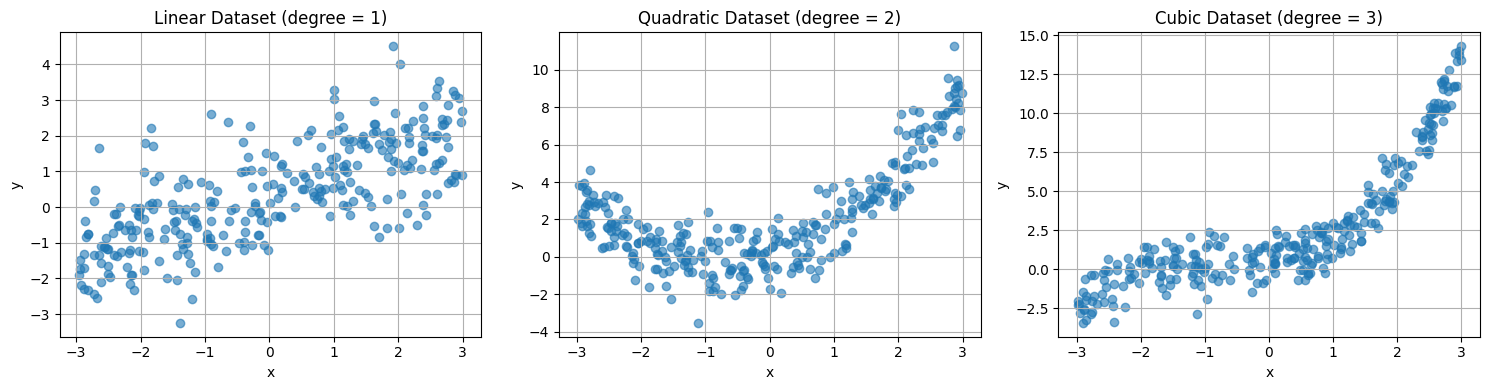

In [15]:
import numpy as np
import matplotlib.pyplot as plt

def generate_polynomial_dataset(degree, n_samples):
    # generate x values between -3 and 3
    x_vals = np.random.uniform(-3, 3, n_samples)

    # generate random coefficients a_0 up to a_degree from U(0, 1)
    coeffs = np.random.uniform(0, 1, degree + 1)

    # generate the noise term epsilon from N(0, 1)
    noise_term = np.random.normal(0, 1, n_samples)

    # start y off at 0, then build the polynomial up term by term
    y_vals = np.zeros(n_samples)
    for power in range(degree + 1):
        y_vals += coeffs[power] * (x_vals ** power)

    # add the noise at the end so it is not too perfectly clean
    y_vals += noise_term

    return x_vals, y_vals

# just testing that the function works for a few different degrees
x_linear, y_linear = generate_polynomial_dataset(degree=1, n_samples=300)
x_quadratic, y_quadratic = generate_polynomial_dataset(degree=2, n_samples=300)
x_cubic, y_cubic = generate_polynomial_dataset(degree=3, n_samples=300)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.scatter(x_linear, y_linear, alpha=0.6)
plt.title("Linear Dataset (degree = 1)")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)

plt.subplot(1, 3, 2)
plt.scatter(x_quadratic, y_quadratic, alpha=0.6)
plt.title("Quadratic Dataset (degree = 2)")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)

plt.subplot(1, 3, 3)
plt.scatter(x_cubic, y_cubic, alpha=0.6)
plt.title("Cubic Dataset (degree = 3)")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)

plt.tight_layout()
plt.show()

**2. Generate three toy datasets using your function: a linear, a quadratic, and cubic dataset. Use n_samples = 1000. Make sure you have a training and test set for each dataset.**

In [16]:
from sklearn.model_selection import train_test_split

# generating the three toy datasets with 1000 samples each
x_linear, y_linear = generate_polynomial_dataset(degree=1, n_samples=1000)
x_quadratic, y_quadratic = generate_polynomial_dataset(degree=2, n_samples=1000)
x_cubic, y_cubic = generate_polynomial_dataset(degree=3, n_samples=1000)

# sklearn likes 2D feature arrays, so reshaping x into column vectors
x_linear = x_linear.reshape(-1, 1)
x_quadratic = x_quadratic.reshape(-1, 1)
x_cubic = x_cubic.reshape(-1, 1)

# splitting each dataset into training and test sets
x_linear_train, x_linear_test, y_linear_train, y_linear_test = train_test_split(
    x_linear, y_linear, test_size=0.2, random_state=42
)

x_quadratic_train, x_quadratic_test, y_quadratic_train, y_quadratic_test = train_test_split(
    x_quadratic, y_quadratic, test_size=0.2, random_state=42
)

x_cubic_train, x_cubic_test, y_cubic_train, y_cubic_test = train_test_split(
    x_cubic, y_cubic, test_size=0.2, random_state=42
)

# just checking the shapes so I know the splits worked properly
print("Linear train/test shapes:", x_linear_train.shape, x_linear_test.shape)
print("Quadratic train/test shapes:", x_quadratic_train.shape, x_quadratic_test.shape)
print("Cubic train/test shapes:", x_cubic_train.shape, x_cubic_test.shape)

Linear train/test shapes: (800, 1) (200, 1)
Quadratic train/test shapes: (800, 1) (200, 1)
Cubic train/test shapes: (800, 1) (200, 1)


**3. Experiment with fitting a sklearn.svm.SVR model to each of the three datasets using kernel=’linear’, kernel=’poly’ and kernel=’rbf’.**